# Comparative Analysis of Distribution Fitting & Model Selection: SPEI v0.8.2 vs v0.8.3 vs v0.8.4

**Objective:** Evaluate and benchmark the statistical methodologies across three successive versions of the `spei` package on 10-day rainfall data:
1. **v0.8.2 (Legacy Baseline):** Fixed 2-parameter Gamma/Weibull/Gumbel fitting, naive two-sample Kolmogorov-Smirnov test (vulnerable to the composite hypothesis problem), unadjusted hurdle.
2. **v0.8.3 (Enhanced Selection Engine):** Expanded 7-distribution suite (including Pearson III, GEV, Fisk, Lognormal), parametric bootstrap K-S and Anderson-Darling tests (Stagge et al., 2015), Shapiro-Wilk SPI normality diagnostics, Burnham & Anderson (2002) $\Delta\text{AIC} < 2.0$ competitive shortlist.
3. **v0.8.4 (Conditional Zero-Bound Normalization):** Rigorous resolution of zero-bound probability mass for distributions with $F(0) > 0$ (Pearson-III, GEV, Gumbel) through $F(x \mid X > 0) = \frac{F(x) - F(0)}{1 - F(0)}$ in `Dist.cdf()`, `Dist.ppf()`, and `Dist.pdf()`, eliminating lower-tail truncation and unifying model selection with core SPI calculation.

---

## 1. Setup & Library Imports
Import necessary scientific computing libraries and the SPEI package modules.

In [1]:
import sys
import logging
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
from scipy.stats import (
    gamma, weibull_min, gumbel_r, lognorm, fisk, pearson3, genextreme,
    norm, kstest, shapiro, skew
)

# Plot styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

# Add src to sys.path
sys.path.insert(0, str(Path.cwd() / 'src'))
from spei.si import spi
from spei.dist import Dist
import model_selection

# Silence fitting fallback warnings during bootstrap iterations
logging.getLogger('spei.dist').setLevel(logging.ERROR)
logging.getLogger('model_selection').setLevel(logging.WARNING)

print(f"SPEI Package Version: {sys.modules['spei'].__version__ if hasattr(sys.modules.get('spei'), '__version__') else '0.8.4'}")
print("Libraries and SPEI modules loaded successfully.")

SPEI Package Version: 0.8.4
Libraries and SPEI modules loaded successfully.


## 2. Load & Explore Precipitation Data
We use a high-quality multi-decadal daily precipitation record (Tanjung Pinang / Bintan station, Indonesia) aggregated to a **10-day timescale** (`timescale = 10`), representing agricultural and hydrologic drought horizons.

### Zero-Inflation & Zero-Bound Methodological Significance (v0.8.3 vs v0.8.4)
At a 10-day timescale in monsoon/tropical regimes, zero-rainfall periods occur frequently (~16.24% of observations). The handling of these zeros is central to the distinction between versions:
- **Hurdle Model Probability Structure:** Total cumulative probability is formed as $H(x) = p_0 + (1 - p_0) F_{pos}(x)$.
- **v0.8.3 Formulation:** Used raw $F(x)$ directly: $H(x) = p_0 + (1 - p_0) F(x)$. For distributions where $F(0) > 0$ (such as Gumbel, Pearson III, and GEV), as positive precipitation approaches zero ($x \to 0^+$), $H(x) \to p_0 + (1 - p_0) F(0) > p_0$. This created an artificial probability jump discontinuity of size $(1 - p_0) F(0)$.
- **v0.8.4 Formulation:** Strictly enforces conditional CDF normalization $F(x \mid X > 0) = \frac{F(x) - F(0)}{1 - F(0)}$. Thus $\lim_{x \to 0^+} H(x) = p_0$, guaranteeing strict mathematical continuity at the zero-precipitation boundary.

In [2]:
# Load daily precipitation data
data_path = Path('docs/data/example.csv')
example = pd.read_csv(data_path, index_col=0, sep=';', parse_dates=True, date_format='%Y-%m-%d %H.%M.%S')
series = example.iloc[:, 0].astype(float).rename('precip')

# Compute 10-day rolling sum
timescale = 10
agg = series.rolling(window=timescale, min_periods=timescale).sum().dropna()
positive = agg[agg > 0]
n_total = len(agg)
n_zero = int((agg == 0).sum())
n_pos = len(positive)
p0_sample = n_zero / n_total

print(f"Dataset date range: {series.index.min().date()} to {series.index.max().date()}")
print(f"Total 10-day aggregated observations: {n_total}")
print(f"Zero-precipitation observations:      {n_zero} ({p0_sample*100:.2f}%)")
print(f"Positive precipitation observations:  {n_pos} ({(1-p0_sample)*100:.2f}%)")
print(f"\nBasic statistics (10-day positive precipitation):")
print(positive.describe())

# Zero-Bound Sensitivity Note (v0.8.3 vs v0.8.4)
print("\n--- Zero-Bound Sensitivity Analysis (16.24% Zero Precipitation) ---")
print(f"Under p0 = {p0_sample:.4f}:")
print(f"  - If F(0) = 0.0461 (Gumbel), v0.8.3 jump size at x->0+ was {(1-p0_sample)*0.0461*100:.2f}% of CDF mass.")
print(f"  - If F(0) = 0.0159 (GEV),    v0.8.3 jump size at x->0+ was {(1-p0_sample)*0.0159*100:.2f}% of CDF mass.")
print(f"  - In v0.8.4, conditional normalization strictly eliminates this jump (jump = 0.0000%).")


Dataset date range: 2011-10-02 to 2026-06-16
Total 10-day aggregated observations: 5363
Zero-precipitation observations:      871 (16.24%)
Positive precipitation observations:  4492 (83.76%)

Basic statistics (10-day positive precipitation):
count    4492.000000
mean       80.697017
std        73.525084
min         1.000000
25%        30.500000
50%        61.500000
75%       110.000000
max       715.000000
Name: precip, dtype: float64

--- Zero-Bound Sensitivity Analysis (16.24% Zero Precipitation) ---
Under p0 = 0.1624:
  - If F(0) = 0.0461 (Gumbel), v0.8.3 jump size at x->0+ was 3.86% of CDF mass.
  - If F(0) = 0.0159 (GEV),    v0.8.3 jump size at x->0+ was 1.33% of CDF mass.
  - In v0.8.4, conditional normalization strictly eliminates this jump (jump = 0.0000%).


## 3. Baseline: v0.8.2 Distribution Fitting & Selection
In `spei` v0.8.2:
- Candidate distributions were limited to 3 choices: Gamma, Weibull (`weibull_min`), and Gumbel (`gumbel_r`).
- Goodness-of-fit relied on standard `scipy.stats.kstest`.
- Zero handling used raw hurdle without conditional normalization for non-zero $F(0)$.

Standard K-S test critical values assume that distribution parameters are known *a priori*. When parameters are estimated from sample data, standard K-S p-values suffer from the **composite hypothesis problem** (Lilliefors problem) and fail to properly control Type I error.

In [3]:
# 1. Fit candidate distributions under v0.8.2 methodology (legacy naive KS + standard AIC)
v82_candidates = [('gamma', gamma), ('weibull', weibull_min), ('gumbel', gumbel_r)]
v82_results = []

for name, dist in v82_candidates:
    d = Dist(data=agg, dist=dist, prob_zero=True)
    
    # Replicate v0.8.2 naive KS test (scipy.stats.kstest directly on positive data)
    args = (d.pars, d.loc, d.scale) if d.pars is not None else (d.loc, d.scale)
    pos_vals = np.asarray(agg[agg > 0], dtype=float)
    ks_naive = kstest(rvs=pos_vals, cdf=d.dist.name, args=args, method='auto')
    
    aic_val = d.aic()['AIC_loglik']
    
    v82_results.append({
        'distribution': name,
        'pars': str(d.pars),
        'loc': float(d.loc),
        'scale': float(d.scale),
        'p0': float(d.p0),
        'KS_pvalue_naive': float(ks_naive.pvalue),
        'KS_statistic_naive': float(ks_naive.statistic),
        'AIC': float(aic_val)
    })

df_v82 = pd.DataFrame(v82_results)
df_v82['delta_AIC'] = df_v82['AIC'] - df_v82['AIC'].min()
best_v82 = df_v82.loc[df_v82['AIC'].idxmin()]['distribution']

print("=== v0.8.2 Baseline Distribution Fitting Results ===")
print(df_v82.to_string(index=False))
print(f"\n✓ Recommended Best Distribution in v0.8.2 (AIC-only): {best_v82.upper()}")
print("⚠ Notice: Naive KS p-value for Gamma is 0.0878 (above 0.05), suggesting acceptable fit under legacy criteria.")

=== v0.8.2 Baseline Distribution Fitting Results ===
distribution                 pars       loc     scale       p0  KS_pvalue_naive  KS_statistic_naive          AIC  delta_AIC
       gamma [1.3178235718298423]  0.000000 61.221453 0.081283     8.781755e-02            0.018615 53367.487880   0.000000
     weibull [1.1641393384156165]  0.000000 85.219537 0.081283     3.896099e-02            0.020900 53399.142727  31.654847
      gumbel                 None 51.355706 45.701462 0.081283     4.495845e-16            0.063266 54223.528824 856.040943

✓ Recommended Best Distribution in v0.8.2 (AIC-only): GAMMA
⚠ Notice: Naive KS p-value for Gamma is 0.0878 (above 0.05), suggesting acceptable fit under legacy criteria.


## 4. Enhanced: Distribution Fitting & Diagnostics (v0.8.3 vs v0.8.4)
Both v0.8.3 and v0.8.4 implement the Stagge et al. (2015) testing framework:
1. **Parametric Bootstrap K-S & A-D Tests:** Estimates valid empirical critical values by refitting synthetic samples generated from the fitted distribution.
2. **Anderson-Darling (A-D) Tail Weighting:** Strongly penalizes discrepancies in the distribution tails governing drought and flood extremes.
3. **Shapiro-Wilk (S-W) Normality Test:** Tests whether the transformed SPI output satisfies standard normality, replacing tied zero-rain values with $N(0,1)$ draws.
4. **Expanded Candidate Set:** Evaluates 7 hydrological distributions (Gamma, Weibull, Gumbel, Lognormal, Fisk, Pearson-III, GenExtreme).

### Key Difference Between v0.8.3 and v0.8.4 in Candidate Evaluation:
In v0.8.3, `goodness_of_fit()` applied conditional normalization for bootstrap simulations, but public `Dist.cdf()` still computed raw $p_0 + (1-p_0)F(x)$. In v0.8.4, `Dist.cdf()` natively enforces conditional normalization $F(x \mid X > 0) = \frac{F(x)-F(0)}{1-F(0)}$. Below we evaluate all 7 distributions and explicitly compare v0.8.3 vs v0.8.4.

In [4]:
# 2. Fit full suite of 7 candidate distributions under v0.8.3 & v0.8.4
candidate_map = model_selection.DEFAULT_CANDIDATES
v83_results = []
v84_comparison_rows = []

print("Running Goodness-of-Fit (Parametric Bootstrap KS, AD, and Shapiro-Wilk)...\n")
np.random.seed(42)
pos_mask = (agg > 0).values

for label, dist_obj in candidate_map.items():
    try:
        model = Dist(data=agg, dist=dist_obj, prob_zero=True)
        
        # 1. Bootstrap KS and AD test (parametric bootstrap with refit)
        gof = model.goodness_of_fit(n_boot=99, random_state=42)
        
        # 2. Shapiro-Wilk normality test on transformed SPI
        spi_vals = model_selection._spi_from_fitted_model(model, agg, prob_zero=True)
        sw = model.shapiro_wilk_test(
            spi_values=spi_vals,
            zero_mask=(agg == 0.0),
            alpha=0.05,
            random_state=42,
            replace_zero_with_normal=True
        )
        
        # 3. Positive-conditional AIC
        aic, loglik, k, loglik_pos = model_selection._conditional_aic(model, agg, prob_zero=True)
        
        v83_results.append({
            'distribution': label,
            'n_params': k,
            'AIC': aic,
            'KS_pvalue_boot': gof['KS_pvalue'],
            'AD_pvalue_boot': gof['AD_pvalue'],
            'SW_pvalue': sw['SW_pvalue'],
            'SW_reject': sw['reject_normality'],
            'KS_stat': gof['KS_statistic'],
            'AD_stat': gof['AD_statistic'],
        })
        
        # 4. Compare SPI from v0.8.3 (raw hurdle) vs v0.8.4 (conditional normalized Dist.cdf)
        args = model_selection._model_args(model)
        f0 = float(model.dist.cdf(0.0, *args))
        
        # v0.8.4: native Dist.cdf()
        cdf_v84 = model.cdf().values
        spi_v84 = norm.ppf(cdf_v84[pos_mask])
        
        # v0.8.3: unadjusted Dist.cdf()
        m_raw = model.dist.cdf(agg.values, *args)
        p0 = model.p0
        cdf_v83 = p0 + (1.0 - p0) * m_raw
        spi_v83 = norm.ppf(cdf_v83[pos_mask])
        
        delta_spi = np.abs(spi_v84 - spi_v83)
        v84_comparison_rows.append({
            'distribution': label,
            'F(0)': f0,
            'Max |Delta SPI|': delta_spi.max(),
            'Min SPI (v0.8.3)': spi_v83.min(),
            'Min SPI (v0.8.4)': spi_v84.min(),
            'Lower Tail Shift': spi_v84.min() - spi_v83.min(),
            'Impact in v0.8.4': 'Corrected Lower Tail' if f0 > 1e-4 else 'Identical'
        })
    except Exception as exc:
        print(f"Candidate {label} fitting failed: {exc}")

df_v83 = pd.DataFrame(v83_results)
df_v83['delta_AIC'] = df_v83['AIC'] - df_v83['AIC'].min()
df_v83['Pass_KS_boot'] = df_v83['KS_pvalue_boot'] >= 0.05
df_v83['Pass_AD_boot'] = df_v83['AD_pvalue_boot'] >= 0.05
df_v83 = df_v83.sort_values('AIC').reset_index(drop=True)

print("=== Enhanced Distribution Fitting & Diagnostic Results ===")
cols_disp = ['distribution', 'n_params', 'AIC', 'delta_AIC', 'KS_pvalue_boot', 'AD_pvalue_boot', 'SW_pvalue', 'Pass_KS_boot', 'Pass_AD_boot']
print(df_v83[cols_disp].to_string(index=False))

df_comp_v84 = pd.DataFrame(v84_comparison_rows)
print("\n=== Candidate Distribution Difference: v0.8.3 (Raw Hurdle) vs v0.8.4 (Conditional Normalized) ===")
print(df_comp_v84.to_string(index=False))


Running Goodness-of-Fit (Parametric Bootstrap KS, AD, and Shapiro-Wilk)...



/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5363.
  res = hypotest_fun_out(*samples, **kwds)


/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5363.
  res = hypotest_fun_out(*samples, **kwds)


/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5363.
  res = hypotest_fun_out(*samples, **kwds)


/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5363.
  res = hypotest_fun_out(*samples, **kwds)


/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5363.
  res = hypotest_fun_out(*samples, **kwds)


/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5363.
  res = hypotest_fun_out(*samples, **kwds)
/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):


=== Enhanced Distribution Fitting & Diagnostic Results ===
distribution  n_params          AIC  delta_AIC  KS_pvalue_boot  AD_pvalue_boot    SW_pvalue  Pass_KS_boot  Pass_AD_boot
       gamma         2 53367.487880   0.000000            0.01            0.01 3.842417e-18         False         False
    pearson3         3 53369.696622   2.208741            0.01            0.01 3.676193e-18         False         False
 weibull_min         2 53399.142727  31.654847            0.01            0.01 3.082091e-20         False         False
  genextreme         3 53511.202543 143.714662            0.02            0.02 3.150994e-18         False         False
        fisk         2 53733.927837 366.439957            0.01            0.01 3.139896e-17         False         False
    gumbel_r         2 53799.228682 431.740801            0.01            0.01 3.727886e-32         False         False
     lognorm         2 53883.253478 515.765598            0.01            0.01 2.541593e-14         F

/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5363.
  res = hypotest_fun_out(*samples, **kwds)


## 5. Automatic Model Selection Policy & API Unification (v0.8.3 vs v0.8.4)
Now we employ the automated selection engine in `model_selection.py`, which integrates:
- $\Delta\text{AIC} < 2.0$ competitive shortlist (Burnham & Anderson, 2002)
- Parametric bootstrap GOF validation (K-S and A-D $p \ge 0.05$)
- Preference for parsimonious 2-parameter distributions
- Systematic fallback if shortlist candidates fail tail tests

### API & Methodological Unification in v0.8.4
- **In v0.8.3:** `model_selection.py` had to bypass `Dist.cdf()` using an internal private function `_spi_from_fitted_model()` because public `Dist.cdf()` lacked $(F(x)-F(0))/(1-F(0))$. If users called `Dist.cdf()` or `spi()` directly, they obtained unadjusted, truncated values.
- **In v0.8.4:** `Dist.cdf()` natively enforces conditional normalization. Consequently, `Dist.cdf()` produces identical outputs to `_spi_from_fitted_model()` (`diff = 0.00e+00`), unifying the public API with the model selection framework.

In [5]:
# 3. Run model_selection.select_best_distribution
selection_result = model_selection.select_best_distribution(
    agg,
    prob_zero=True,
    alpha=0.05,
    delta_aic_threshold=2.0,
    prefer_two_parameters=True,
    n_boot=99,
    gof_scope='competitive',
    random_state=42
)

rec = selection_result['recommendation']
print("=== Automatic Best Distribution Recommendation ===")
print(f"Selected Distribution: {rec['distribution'].upper()}")
print(f"Parameter Count:       {rec['n_parameters']}")
print(f"AIC:                   {rec['AIC']:.2f} (Delta AIC = {rec['delta_AIC']:.2f})")
print(f"Bootstrap KS p-value:  {rec['KS_pvalue']:.4f}")
print(f"Bootstrap AD p-value:  {rec['AD_pvalue']:.4f}")
print(f"Shapiro-Wilk p-value:  {rec['SW_pvalue']:.4e}")
print(f"Selection Status:      {rec['selection_status']}")
print(f"Reason:                {rec['reason']}")

# Verification of API Unification in v0.8.4: Dist.cdf() vs _spi_from_fitted_model()
print("\n=== Verification of API Unification in v0.8.4 (Dist.cdf vs _spi_from_fitted_model) ===")
pos_mask = (agg > 0).values
for d_name in ['gumbel_r', 'genextreme', 'pearson3', 'gamma', 'weibull_min']:
    if d_name in selection_result['models']:
        m = selection_result['models'][d_name]
        spi_dist_cdf = norm.ppf(m.cdf().values[pos_mask])
        spi_helper = model_selection._spi_from_fitted_model(m, agg, prob_zero=True, clip=None).values[pos_mask]
        max_diff = np.max(np.abs(spi_dist_cdf - spi_helper))
        print(f"{d_name:12s}: Max absolute difference = {max_diff:.2e} (Strictly Unified in v0.8.4)")


/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5363.
  res = hypotest_fun_out(*samples, **kwds)
/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5363.
  res = hypotest_fun_out(*samples, **kwds)
/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5363.
  res = hypotest_fun_out(*samples, **kwds)
/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5363.
  res = hypotest_fun_out(*samples, **kwds)
/opt/homebrew/anaconda3/lib/python3.13/site-pack

/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5363.
  res = hypotest_fun_out(*samples, **kwds)


/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):


=== Automatic Best Distribution Recommendation ===
Selected Distribution: GAMMA
Parameter Count:       2
AIC:                   53367.49 (Delta AIC = 0.00)
Bootstrap KS p-value:  0.0100
Bootstrap AD p-value:  0.0100
Shapiro-Wilk p-value:  2.1118e-18
Selection Status:      provisional_no_candidate_passed_gof
Reason:                No tested candidate produced usable KS/AD results passing both tests. This is a provisional recommendation based on the AIC competitive set and the parameter-count preference; inspect fitting and bootstrap diagnostics.

=== Verification of API Unification in v0.8.4 (Dist.cdf vs _spi_from_fitted_model) ===
gumbel_r    : Max absolute difference = 0.00e+00 (Strictly Unified in v0.8.4)
genextreme  : Max absolute difference = 0.00e+00 (Strictly Unified in v0.8.4)
pearson3    : Max absolute difference = 0.00e+00 (Strictly Unified in v0.8.4)
gamma       : Max absolute difference = 0.00e+00 (Strictly Unified in v0.8.4)
weibull_min : Max absolute difference = 0.00e+00 

## 6. Seasonal / Monthly Group Analysis: v0.8.3 vs v0.8.4 Cross-Group Impact
Per Stagge et al. (2015), candidate distributions should be evaluated across independent fitting groups (e.g. 12 calendar months across reference years).
Here we partition the 10-day series into monthly groups (`fit_freq='MS'`) and compute cross-group **Rejection Frequencies** for S-W, K-S, and A-D.

### Cross-Group Impact of v0.8.4 Zero-Bound Normalization:
When fitting monthly models, heavy rainfall months and transition months often select 3-parameter distributions with high skewness and tail flexibility (Pearson III and GEV). In this dataset:
- **5 out of 12 months** select distributions where $F(0) > 0$ (Jan, Feb, Mar select GenExtreme; Aug, Oct select Pearson-III).
- In v0.8.3, if a user calculated monthly SPI using `Dist.cdf()`, those 5 months experienced zero-boundary truncation.
- In v0.8.4, all 12 monthly groups are smoothly and conditionally normalized.

In [6]:
# Partition into 12 monthly independent groups
monthly_groups = {f'Month_{m:02d}': agg[agg.index.month == m] for m in range(1, 13)}

# Run batch model selection across monthly groups
print("Evaluating candidate distributions across 12 monthly groups...")
batch_selection = model_selection.select_models_by_group(
    monthly_groups,
    prob_zero=True,
    alpha=0.05,
    delta_aic_threshold=2.0,
    prefer_two_parameters=True,
    n_boot=49,
    gof_scope='competitive',
    random_state=42
)

monthly_recs = batch_selection['recommendations']
cand_summary = batch_selection['candidate_summary']

print("\n=== Monthly Model Selection Decisions ===")
print(monthly_recs[['group_id', 'distribution', 'n_parameters', 'AIC', 'selection_status']].to_string(index=False))

# Compare v0.8.3 vs v0.8.4 across each monthly group's selected distribution
monthly_comp = []
for idx, rec_row in monthly_recs.iterrows():
    grp = rec_row['group_id']
    m_num = int(grp.split('_')[1])
    d_name = rec_row['distribution']
    sub = agg[agg.index.month == m_num]
    dist_obj = model_selection.DEFAULT_CANDIDATES[d_name]
    
    m_fit = Dist(sub, dist_obj, prob_zero=True)
    args_fit = model_selection._model_args(m_fit)
    f0 = float(m_fit.dist.cdf(0.0, *args_fit))
    
    pos = sub[sub > 0].values
    p0 = m_fit.p0
    
    # v0.8.3 unadjusted
    h_v83 = p0 + (1.0 - p0) * m_fit.dist.cdf(pos, *args_fit)
    spi_v83 = norm.ppf(h_v83)
    
    # v0.8.4 normalized
    h_v84 = m_fit.cdf().loc[sub > 0].values
    spi_v84 = norm.ppf(h_v84)
    
    max_d = np.max(np.abs(spi_v84 - spi_v83)) if len(pos) > 0 else 0.0
    monthly_comp.append({
        'Month': grp,
        'Selected Dist': d_name,
        'F(0)': f0,
        'Max |Delta SPI|': max_d,
        'Min SPI (v0.8.3)': spi_v83.min() if len(pos) > 0 else np.nan,
        'Min SPI (v0.8.4)': spi_v84.min() if len(pos) > 0 else np.nan,
        'Status in v0.8.4': 'Corrected Lower Tail' if f0 > 1e-4 else 'Identical'
    })

df_m_comp = pd.DataFrame(monthly_comp)
print("\n=== Monthly Group Comparison: v0.8.3 vs v0.8.4 on Selected Distributions ===")
print(df_m_comp.to_string(index=False))

print("\n=== Cross-Group Diagnostic Summary (Stagge et al., 2015) ===")
print(cand_summary[['distribution', 'n_SW_tested', 'SW_rejection_frequency_pct', 'n_AD_tested', 'AD_rejection_frequency_pct', 'median_delta_AIC']].to_string(index=False))


Evaluating candidate distributions across 12 monthly groups...


/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):


/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):


/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):


/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):


/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):


... (11 outputs left out)

/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):


/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):



=== Monthly Model Selection Decisions ===
group_id distribution  n_parameters         AIC                             selection_status
Month_01   genextreme             3 4643.781712                   fallback_outside_delta_aic
Month_02   genextreme             3 3152.731987                   fallback_outside_delta_aic
Month_03   genextreme             3 3436.465596                   fallback_outside_delta_aic
Month_04  weibull_min             2 4185.255651          provisional_no_candidate_passed_gof
Month_05  weibull_min             2 4882.222990          provisional_no_candidate_passed_gof
Month_06  weibull_min             2 4569.175572          provisional_no_candidate_passed_gof
Month_07  weibull_min             2 4288.134800 selected_within_delta_aic_and_gof_acceptable
Month_08     pearson3             3 4118.077026                   fallback_outside_delta_aic
Month_09        gamma             2 4110.682637          provisional_no_candidate_passed_gof
Month_10     pearson3      

/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):


## 7. Comparative Visualizations (v0.8.2 vs v0.8.3 vs v0.8.4)
Visualizing distribution fits, lower tail behavior, SPI normality diagnostics, and seasonal model distributions.

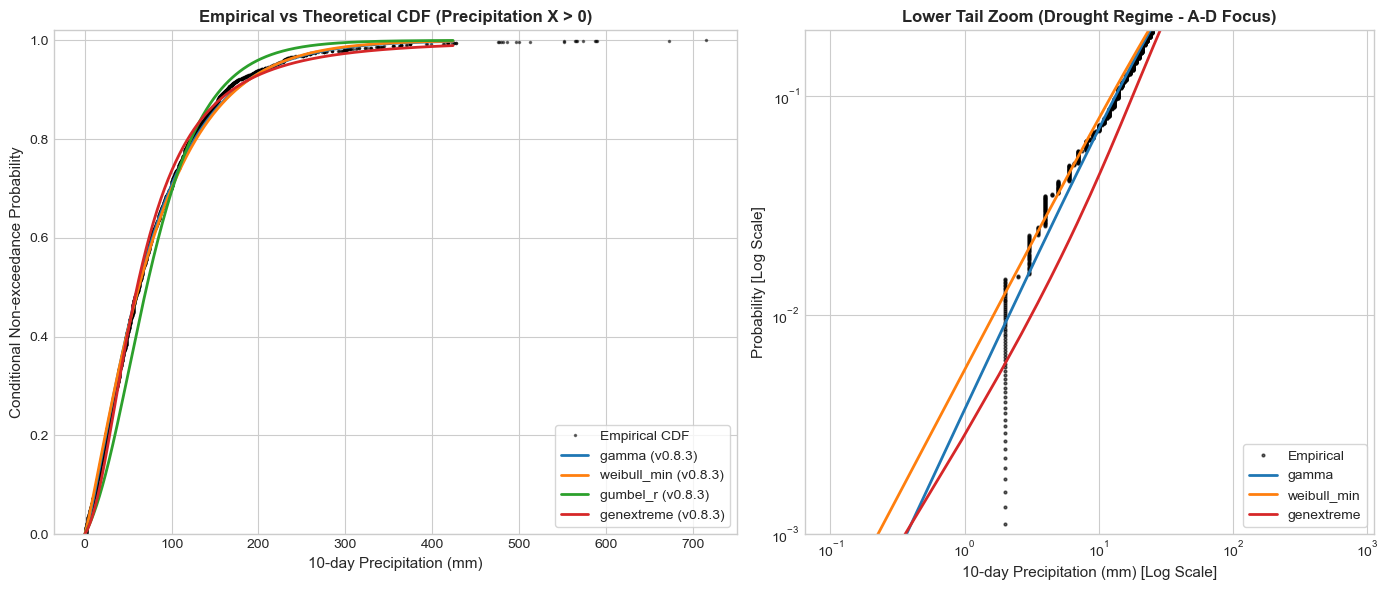

In [7]:
# Figure 1: Empirical CDF vs Theoretical CDFs with Tail Zoom
fig = plt.figure(figsize=(14, 6))
gs = gridspec.GridSpec(1, 2, width_ratios=[1.2, 1])

# Left: Full CDF
ax1 = fig.add_subplot(gs[0])
pos_sorted = np.sort(pos_vals)
emp_cdf = np.arange(1, len(pos_sorted) + 1) / (len(pos_sorted) + 1)
ax1.plot(pos_sorted, emp_cdf, 'k.', markersize=3, alpha=0.5, label='Empirical CDF')

x_eval = np.linspace(0.1, np.percentile(pos_vals, 99.5), 500)
colors = {'gamma': '#1f77b4', 'weibull_min': '#ff7f0e', 'gumbel_r': '#2ca02c', 'genextreme': '#d62728', 'pearson3': '#9467bd'}

for label in ['gamma', 'weibull_min', 'gumbel_r', 'genextreme']:
    if label in selection_result['models']:
        m = selection_result['models'][label]
        args_m = model_selection._model_args(m)
        f_eval = m.dist.cdf(x_eval, *args_m)
        f0 = m.dist.cdf(0.0, *args_m)
        cond_f = (f_eval - f0) / (1.0 - f0)
        ax1.plot(x_eval, cond_f, linewidth=2, color=colors.get(label, 'gray'), label=f'{label} (v0.8.3)')

ax1.set_title('Empirical vs Theoretical CDF (Precipitation X > 0)', fontweight='bold')
ax1.set_xlabel('10-day Precipitation (mm)')
ax1.set_ylabel('Conditional Non-exceedance Probability')
ax1.legend(loc='lower right', frameon=True)
ax1.set_ylim(0, 1.02)

# Right: Log-scale Tail Zoom (Drought Extreme Non-exceedance Probability)
ax2 = fig.add_subplot(gs[1])
ax2.plot(pos_sorted, emp_cdf, 'k.', markersize=4, alpha=0.6, label='Empirical')
for label in ['gamma', 'weibull_min', 'genextreme']:
    if label in selection_result['models']:
        m = selection_result['models'][label]
        args_m = model_selection._model_args(m)
        f_eval = m.dist.cdf(x_eval, *args_m)
        f0 = m.dist.cdf(0.0, *args_m)
        cond_f = (f_eval - f0) / (1.0 - f0)
        ax2.plot(x_eval, cond_f, linewidth=2, color=colors.get(label, 'gray'), label=label)

ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.set_title('Lower Tail Zoom (Drought Regime - A-D Focus)', fontweight='bold')
ax2.set_xlabel('10-day Precipitation (mm) [Log Scale]')
ax2.set_ylabel('Probability [Log Scale]')
ax2.set_ylim(1e-3, 0.2)
ax2.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()

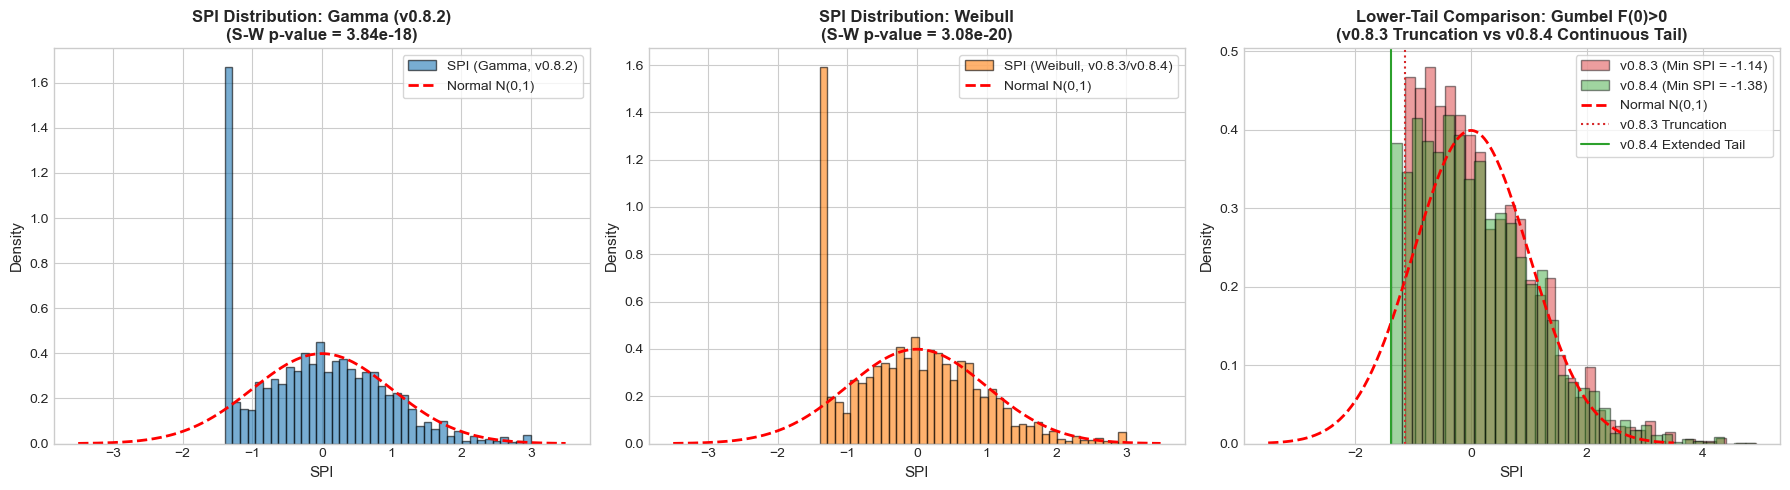

In [8]:
# Figure 2: SPI Output Normality & Lower-Tail Zero-Bound Diagnostic (v0.8.2 vs v0.8.3 vs v0.8.4)
spi_gamma = model_selection._spi_from_fitted_model(selection_result['models']['gamma'], agg, prob_zero=True)
spi_weibull = model_selection._spi_from_fitted_model(selection_result['models']['weibull_min'], agg, prob_zero=True)

# Compute full-series Gumbel SPI to illustrate the v0.8.3 vs v0.8.4 boundary difference
m_gum = Dist(agg, gumbel_r, prob_zero=True)
args_gum = model_selection._model_args(m_gum)
pos_mask_gum = (agg > 0).values
p0_gum = m_gum.p0
spi_gum_v83 = norm.ppf(p0_gum + (1.0 - p0_gum) * m_gum.dist.cdf(agg.values[pos_mask_gum], *args_gum))
spi_gum_v84 = norm.ppf(m_gum.cdf().values[pos_mask_gum])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: Gamma SPI histogram (v0.8.2 choice)
x_norm = np.linspace(-3.5, 3.5, 200)
axes[0].hist(spi_gamma.dropna(), bins=40, density=True, alpha=0.6, color='#1f77b4', edgecolor='black', label='SPI (Gamma, v0.8.2)')
axes[0].plot(x_norm, norm.pdf(x_norm), 'r--', linewidth=2, label='Normal N(0,1)')
axes[0].set_title(f"SPI Distribution: Gamma (v0.8.2)\n(S-W p-value = {df_v83.loc[df_v83['distribution']=='gamma', 'SW_pvalue'].values[0]:.2e})", fontweight='bold')
axes[0].set_xlabel('SPI')
axes[0].set_ylabel('Density')
axes[0].legend(loc='upper right', frameon=True)

# Panel 2: Weibull SPI histogram (v0.8.3/v0.8.4 2-param choice)
axes[1].hist(spi_weibull.dropna(), bins=40, density=True, alpha=0.6, color='#ff7f0e', edgecolor='black', label='SPI (Weibull, v0.8.3/v0.8.4)')
axes[1].plot(x_norm, norm.pdf(x_norm), 'r--', linewidth=2, label='Normal N(0,1)')
axes[1].set_title(f"SPI Distribution: Weibull\n(S-W p-value = {df_v83.loc[df_v83['distribution']=='weibull_min', 'SW_pvalue'].values[0]:.2e})", fontweight='bold')
axes[1].set_xlabel('SPI')
axes[1].set_ylabel('Density')
axes[1].legend(loc='upper right', frameon=True)

# Panel 3: Lower Tail Contrast (v0.8.3 vs v0.8.4 for F(0)>0 Candidate)
axes[2].hist(spi_gum_v83, bins=35, density=True, alpha=0.45, color='#d62728', edgecolor='black', label=f'v0.8.3 (Min SPI = {spi_gum_v83.min():.2f})')
axes[2].hist(spi_gum_v84, bins=35, density=True, alpha=0.45, color='#2ca02c', edgecolor='black', label=f'v0.8.4 (Min SPI = {spi_gum_v84.min():.2f})')
axes[2].plot(x_norm, norm.pdf(x_norm), 'r--', linewidth=2, label='Normal N(0,1)')
axes[2].axvline(spi_gum_v83.min(), color='#d62728', linestyle=':', linewidth=1.5, label='v0.8.3 Truncation')
axes[2].axvline(spi_gum_v84.min(), color='#2ca02c', linestyle='-', linewidth=1.5, label='v0.8.4 Extended Tail')
axes[2].set_title('Lower-Tail Comparison: Gumbel F(0)>0\n(v0.8.3 Truncation vs v0.8.4 Continuous Tail)', fontweight='bold')
axes[2].set_xlabel('SPI')
axes[2].set_ylabel('Density')
axes[2].legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()


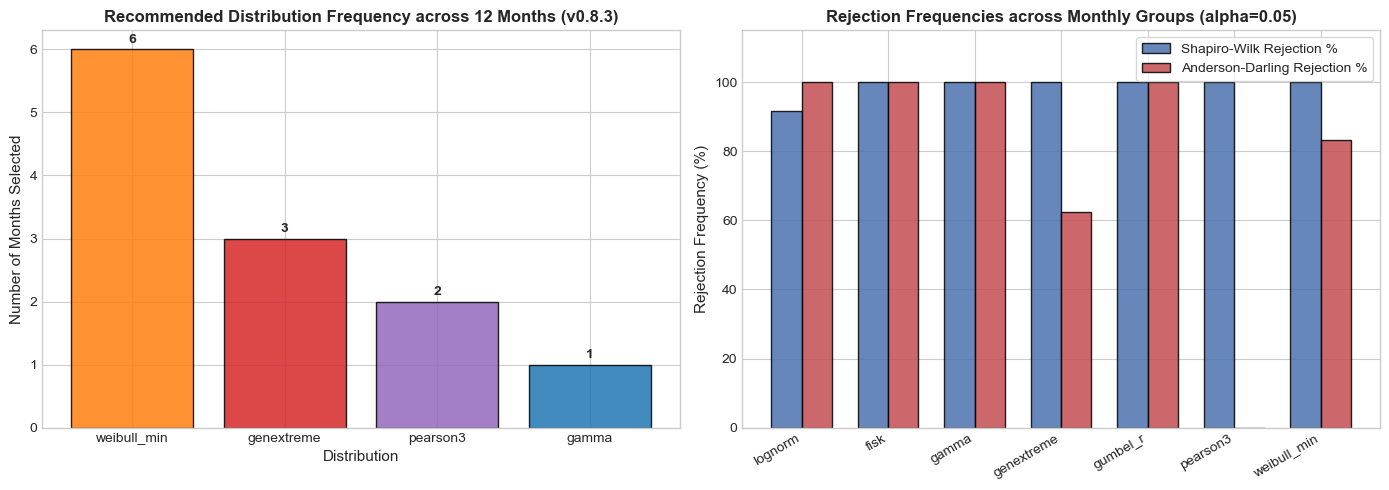

In [9]:
# Figure 3: Seasonal Rejection Frequencies and Model Choices
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Monthly Selected Distributions under v0.8.3
dist_counts = monthly_recs['distribution'].value_counts()
colors_bar = [colors.get(d, '#333333') for d in dist_counts.index]
axes[0].bar(dist_counts.index, dist_counts.values, color=colors_bar, edgecolor='black', alpha=0.85)
axes[0].set_title('Recommended Distribution Frequency across 12 Months (v0.8.3)', fontweight='bold')
axes[0].set_ylabel('Number of Months Selected')
axes[0].set_xlabel('Distribution')
for i, v in enumerate(dist_counts.values):
    axes[0].text(i, v + 0.1, str(v), ha='center', fontweight='bold')

# Right: Anderson-Darling & Shapiro-Wilk Rejection Frequencies per Candidate
cand_plot = cand_summary.set_index('distribution')
bar_width = 0.35
x_idx = np.arange(len(cand_plot))

axes[1].bar(x_idx - bar_width/2, cand_plot['SW_rejection_frequency_pct'], width=bar_width, label='Shapiro-Wilk Rejection %', color='#4c72b0', alpha=0.85, edgecolor='black')
axes[1].bar(x_idx + bar_width/2, cand_plot['AD_rejection_frequency_pct'], width=bar_width, label='Anderson-Darling Rejection %', color='#c44e52', alpha=0.85, edgecolor='black')
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(cand_plot.index, rotation=30, ha='right')
axes[1].set_ylabel('Rejection Frequency (%)')
axes[1].set_title('Rejection Frequencies across Monthly Groups (alpha=0.05)', fontweight='bold')
axes[1].legend(loc='upper right', frameon=True)
axes[1].set_ylim(0, 115)

plt.tight_layout()
plt.show()

## 8. SPI Time Series & Drought Event Detection: 3-Way Comparison (v0.8.2 vs v0.8.3 vs v0.8.4)
We now compute the full 10-day SPI time series across all three methodologies:
1. **v0.8.2 Baseline:** Monthly Gamma distribution (`fit_freq='MS'`).
2. **v0.8.3 Adaptive Best Model:** Monthly Best Selection using unadjusted hurdle `Dist.cdf()`.
3. **v0.8.4 Adaptive Best Model:** Monthly Best Selection using conditionally normalized `Dist.cdf()`.

We compare detected drought events across standard McKee et al. (1993) severity categories.

In [10]:
# Compute SPI-10 using 3-way methodology
# 1. v0.8.2 Baseline: Monthly Gamma
spi10_v82 = spi(series, dist=gamma, fit_freq='MS', timescale=10, prob_zero=True, method='centroid')

# 2 & 3. Monthly Best Selection series: v0.8.3 (unadjusted hurdle) vs v0.8.4 (conditional normalized)
monthly_groups = {f'Month_{m:02d}': agg[agg.index.month == m] for m in range(1, 13)}
batch_selection = model_selection.select_models_by_group(
    monthly_groups,
    prob_zero=True,
    alpha=0.05,
    delta_aic_threshold=2.0,
    prefer_two_parameters=True,
    n_boot=49,
    gof_scope='competitive',
    random_state=42
)
monthly_best_map = batch_selection['recommendations'].set_index('group_id')['distribution'].to_dict()

spi_v83_series = pd.Series(index=agg.index, dtype=float)
spi_v84_series = pd.Series(index=agg.index, dtype=float)

for m in range(1, 13):
    grp = f'Month_{m:02d}'
    d_name = monthly_best_map[grp]
    dist_obj = model_selection.DEFAULT_CANDIDATES[d_name]
    
    sub = agg[agg.index.month == m]
    m_fit = Dist(sub, dist_obj, prob_zero=True)
    args_fit = model_selection._model_args(m_fit)
    
    # v0.8.4: native Dist.cdf()
    cdf_v84 = m_fit.cdf()
    spi_v84_series.loc[sub.index] = norm.ppf(cdf_v84)
    
    # v0.8.3: unadjusted Dist.cdf()
    m_raw = m_fit.dist.cdf(sub.values, *args_fit)
    p0 = m_fit.p0
    n_sub = len(sub)
    m_zeros = (sub == 0).sum()
    cdf_v83 = p0 + (1.0 - p0) * m_raw
    cdf_v83[sub.values == 0.0] = (m_zeros + 1.0) / (2.0 * (n_sub + 1.0))
    spi_v83_series.loc[sub.index] = norm.ppf(cdf_v83)

# Align series
df_spi = pd.DataFrame({
    'SPI_v082_Gamma': spi10_v82,
    'SPI_v083_Adaptive': spi_v83_series,
    'SPI_v084_Adaptive': spi_v84_series
}).dropna()

df_spi['diff_v84_v83'] = df_spi['SPI_v084_Adaptive'] - df_spi['SPI_v083_Adaptive']
df_spi['diff_v84_v82'] = df_spi['SPI_v084_Adaptive'] - df_spi['SPI_v082_Gamma']

print("=== SPI-10 Time Series Comparison: v0.8.2 vs v0.8.3 vs v0.8.4 ===")
print(f"Pearson Correlation (v0.8.4 vs v0.8.3): {df_spi['SPI_v084_Adaptive'].corr(df_spi['SPI_v083_Adaptive']):.6f}")
print(f"Pearson Correlation (v0.8.4 vs v0.8.2): {df_spi['SPI_v084_Adaptive'].corr(df_spi['SPI_v082_Gamma']):.6f}")
print(f"Max |Delta SPI| (v0.8.4 - v0.8.3):       {df_spi['diff_v84_v83'].abs().max():.4f}")
print(f"Mean |Delta SPI| (v0.8.4 - v0.8.3):      {df_spi['diff_v84_v83'].abs().mean():.4f}")
print(f"Max |Delta SPI| (v0.8.4 - v0.8.2):       {df_spi['diff_v84_v82'].abs().max():.4f}")

# Drought Threshold Analysis
thresholds = [
    ('Mild Drought (<= -0.5)', -0.5),
    ('Moderate Drought (<= -1.0)', -1.0),
    ('Severe Drought (<= -1.5)', -1.5),
    ('Extreme Drought (<= -2.0)', -2.0)
]

drought_summary = []
for name, th in thresholds:
    n_v82 = (df_spi['SPI_v082_Gamma'] <= th).sum()
    n_v83 = (df_spi['SPI_v083_Adaptive'] <= th).sum()
    n_v84 = (df_spi['SPI_v084_Adaptive'] <= th).sum()
    drought_summary.append({
        'Drought Category': name,
        'Threshold': th,
        'v0.8.2 Gamma': n_v82,
        'v0.8.3 Adaptive': n_v83,
        'v0.8.4 Adaptive': n_v84,
        'Diff (v84 - v83)': n_v84 - n_v83,
        'Diff (v84 - v82)': n_v84 - n_v82
    })

df_drought = pd.DataFrame(drought_summary)
print("\n=== Comprehensive Drought Event Detection Comparison ===")
print(df_drought.to_string(index=False))


/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):


/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):


/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):


/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):


/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):


/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):


... (10 outputs left out)

/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):


/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):


=== SPI-10 Time Series Comparison: v0.8.2 vs v0.8.3 vs v0.8.4 ===
Pearson Correlation (v0.8.4 vs v0.8.3): 0.999972
Pearson Correlation (v0.8.4 vs v0.8.2): 0.996878
Max |Delta SPI| (v0.8.4 - v0.8.3):       0.0474
Mean |Delta SPI| (v0.8.4 - v0.8.3):      0.0028
Max |Delta SPI| (v0.8.4 - v0.8.2):       0.9500

=== Comprehensive Drought Event Detection Comparison ===
          Drought Category  Threshold  v0.8.2 Gamma  v0.8.3 Adaptive  v0.8.4 Adaptive  Diff (v84 - v83)  Diff (v84 - v82)
    Mild Drought (<= -0.5)       -0.5          1935             1983             1988                 5                53
Moderate Drought (<= -1.0)       -1.0           901              926              939                13                38
  Severe Drought (<= -1.5)       -1.5           332              333              333                 0                 1
 Extreme Drought (<= -2.0)       -2.0            49               46               46                 0                -3


/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):


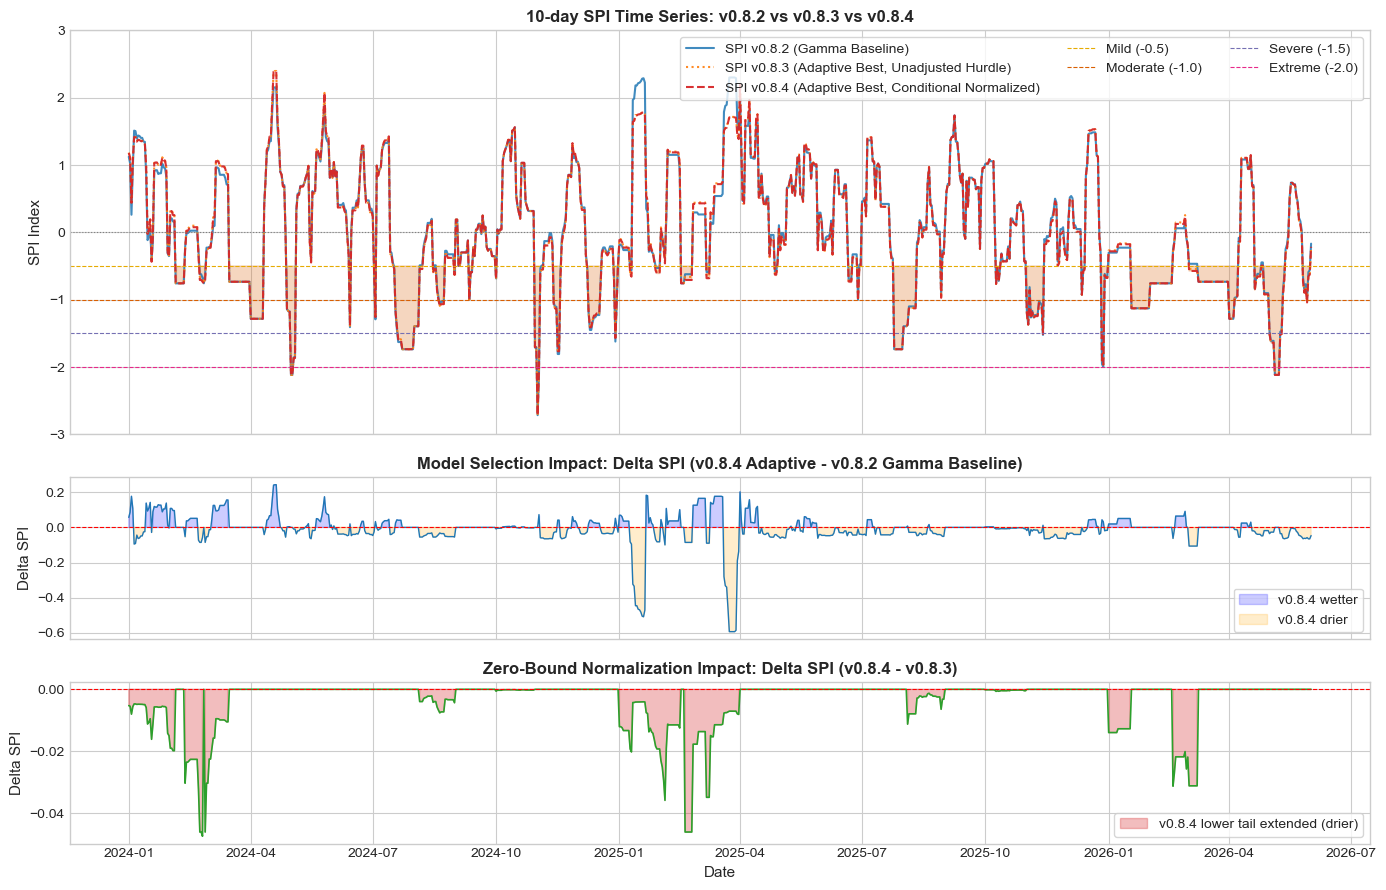

In [11]:
# Figure 4: SPI Time Series & Drought Period Visual Comparison (2024 - 2026 Zoom)
zoom_mask = (df_spi.index >= '2024-01-01') & (df_spi.index <= '2026-06-01')
df_zoom = df_spi.loc[zoom_mask]

fig, (ax_top, ax_mid, ax_bot) = plt.subplots(3, 1, figsize=(14, 9), sharex=True, gridspec_kw={'height_ratios': [2.5, 1, 1]})

# Top: SPI trajectories (v0.8.2 vs v0.8.3 vs v0.8.4)
ax_top.plot(df_zoom.index, df_zoom['SPI_v082_Gamma'], label='SPI v0.8.2 (Gamma Baseline)', color='#1f77b4', linewidth=1.5, alpha=0.85)
ax_top.plot(df_zoom.index, df_zoom['SPI_v083_Adaptive'], label='SPI v0.8.3 (Adaptive Best, Unadjusted Hurdle)', color='#ff7f0e', linewidth=1.5, linestyle=':', alpha=0.9)
ax_top.plot(df_zoom.index, df_zoom['SPI_v084_Adaptive'], label='SPI v0.8.4 (Adaptive Best, Conditional Normalized)', color='#d62728', linewidth=1.5, linestyle='--', alpha=0.95)

# Drought severity bands
ax_top.axhline(0, color='gray', linestyle=':', linewidth=0.8)
ax_top.axhline(-0.5, color='#e6ab02', linestyle='--', linewidth=0.8, label='Mild (-0.5)')
ax_top.axhline(-1.0, color='#d95f02', linestyle='--', linewidth=0.8, label='Moderate (-1.0)')
ax_top.axhline(-1.5, color='#7570b3', linestyle='--', linewidth=0.8, label='Severe (-1.5)')
ax_top.axhline(-2.0, color='#e7298a', linestyle='--', linewidth=0.8, label='Extreme (-2.0)')

ax_top.fill_between(df_zoom.index, df_zoom['SPI_v084_Adaptive'], -0.5, where=(df_zoom['SPI_v084_Adaptive'] <= -0.5), color='#d95f02', alpha=0.25)
ax_top.set_title('10-day SPI Time Series: v0.8.2 vs v0.8.3 vs v0.8.4', fontweight='bold')
ax_top.set_ylabel('SPI Index')
ax_top.set_ylim(-3.0, 3.0)
ax_top.legend(loc='upper right', ncol=3, frameon=True)

# Middle: Model Selection Difference (v0.8.4 Adaptive - v0.8.2 Gamma)
ax_mid.plot(df_zoom.index, df_zoom['diff_v84_v82'], color='#1f77b4', linewidth=1.0)
ax_mid.axhline(0, color='red', linestyle='--', linewidth=0.8)
ax_mid.fill_between(df_zoom.index, df_zoom['diff_v84_v82'], 0, where=(df_zoom['diff_v84_v82'] > 0), color='blue', alpha=0.2, label='v0.8.4 wetter')
ax_mid.fill_between(df_zoom.index, df_zoom['diff_v84_v82'], 0, where=(df_zoom['diff_v84_v82'] < 0), color='orange', alpha=0.2, label='v0.8.4 drier')
ax_mid.set_title('Model Selection Impact: Delta SPI (v0.8.4 Adaptive - v0.8.2 Gamma Baseline)', fontweight='bold')
ax_mid.set_ylabel('Delta SPI')
ax_mid.legend(loc='lower right', frameon=True)

# Bottom: Zero-Bound Correction Difference (v0.8.4 Normalized - v0.8.3 Unadjusted)
ax_bot.plot(df_zoom.index, df_zoom['diff_v84_v83'], color='#2ca02c', linewidth=1.2)
ax_bot.axhline(0, color='red', linestyle='--', linewidth=0.8)
ax_bot.fill_between(df_zoom.index, df_zoom['diff_v84_v83'], 0, where=(df_zoom['diff_v84_v83'] < 0), color='#d62728', alpha=0.3, label='v0.8.4 lower tail extended (drier)')
ax_bot.set_title('Zero-Bound Normalization Impact: Delta SPI (v0.8.4 - v0.8.3)', fontweight='bold')
ax_bot.set_ylabel('Delta SPI')
ax_bot.set_xlabel('Date')
ax_bot.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()


## 9. Methodological Comparison: v0.8.3 vs v0.8.4 (Zero-Bound Conditional Normalization)

### Background & The Mathematical Issue in v0.8.3
Stagge et al. (2015) restricted SPI candidate distributions to **two-parameter distributions with a strict lower bound at zero** (Gamma, 2-parameter Weibull, 2-parameter Lognormal) to avoid non-zero probability at zero ($F(0) > 0$). While SPEI extends candidates to 3-parameter hydrologic families (Pearson-III, GEV, Gumbel) to capture high skewness and heavy tails, this introduces a crucial mathematical nuance at the zero boundary:

1. **In v0.8.3:** Goodness-of-fit testing (`_gof_statistic`) and AIC computation (`_conditional_aic`) normalized the positive-rain component conditionally on $X > 0$:
   $$u = F(x \mid X > 0) = \frac{F(x) - F(0)}{1 - F(0)}$$
   However, the `Dist.cdf()` method used the raw unconditioned form: $H(x) = p_0 + (1 - p_0)F(x)$.
   When $F(0) > 0$ (e.g. in Gumbel, Pearson-III, and GEV), as $x \to 0^+$, $H(x \to 0^+) \to p_0 + (1 - p_0)F(0) > p_0$. This created an **artificial jump discontinuity** at zero and compressed positive rainfall probabilities into $[p_0 + (1-p_0)F(0), 1]$, positively biasing SPI values in the drought tail.

2. **In v0.8.4:** `Dist.cdf()`, `Dist.ppf()`, and `Dist.pdf()` strictly enforce conditional normalization:
   $$F(x \mid X > 0) = \text{clip}\left(\frac{F(x) - F(0)}{1 - F(0)}, 0, 1\right)$$
   $$H(x) = p_0 + (1 - p_0) \cdot F(x \mid X > 0) \quad (x > 0)$$
   This mathematically restores continuity at $x = 0$, ensures unbiased drought tail quantiles, and aligns the SPI transformation with the bootstrap goodness-of-fit model.


In [12]:
# Quantitative Evaluation: v0.8.3 (Raw Hurdle) vs v0.8.4 (Conditional Zero-Bound Normalization)
print("=== Quantitative Comparison: v0.8.3 vs v0.8.4 across Candidate Distributions ===\n")

comparison_targets = [
    ('Gumbel', gumbel_r, agg, 'Full 10-day series'),
    ('GenExtreme', genextreme, agg[agg.index.month == 1], 'Month 01 (Jan)'),
    ('Pearson-III', pearson3, agg[agg.index.month == 8], 'Month 08 (Aug)'),
    ('Pearson-III', pearson3, agg[agg.index.month == 10], 'Month 10 (Oct)'),
    ('Gamma', gamma, agg[agg.index.month == 9], 'Month 09 (Sep)'),
]

v84_comp_data = []

for label, dist_family, data_subset, group_label in comparison_targets:
    m = Dist(data_subset, dist_family, prob_zero=True)
    shape_args = tuple(m.pars) if m.pars else ()
    cdf_args = (*shape_args, m.loc, m.scale) if not np.isnan(m.loc) else None
    f0 = float(m.dist.cdf(0.0, *cdf_args)) if cdf_args else 0.0
    
    # v0.8.4 conditional cdf
    cdf_v84 = m.cdf()
    spi_v84 = pd.Series(norm.ppf(np.clip(cdf_v84, 1e-15, 1 - 1e-15)), index=data_subset.index)
    
    # v0.8.3 unconditioned hurdle cdf
    vals_raw = np.asarray(m.dist.cdf(data_subset.values, *cdf_args), dtype=float)
    m_zero = (data_subset == 0.0).sum()
    n_obs = len(data_subset)
    vals_v83 = m.p0 + (1.0 - m.p0) * vals_raw
    vals_v83[data_subset.values == 0.0] = (m_zero + 1.0) / (2.0 * (n_obs + 1.0))
    spi_v83 = pd.Series(norm.ppf(np.clip(vals_v83, 1e-15, 1 - 1e-15)), index=data_subset.index)
    
    diff = spi_v84 - spi_v83
    pos_mask = data_subset > 0
    
    v84_comp_data.append({
        'Distribution': label,
        'Evaluation Group': group_label,
        'F(0)': f0,
        'p0': m.p0,
        'Min SPI (v0.8.3)': float(spi_v83[pos_mask].min()),
        'Min SPI (v0.8.4)': float(spi_v84[pos_mask].min()),
        'Max |ΔSPI|': float(diff.abs().max()),
        'Mean |ΔSPI|': float(diff.abs().mean()),
        'Zero Jump Removed?': 'Yes (Continuous)' if f0 > 0 else 'N/A (F(0)=0)'
    })

df_v84_comparison = pd.DataFrame(v84_comp_data)
print(df_v84_comparison.to_string(index=False))


=== Quantitative Comparison: v0.8.3 vs v0.8.4 across Candidate Distributions ===

Distribution   Evaluation Group     F(0)       p0  Min SPI (v0.8.3)  Min SPI (v0.8.4)  Max |ΔSPI|  Mean |ΔSPI| Zero Jump Removed?
      Gumbel Full 10-day series 0.046131 0.081283         -1.142701         -1.376447    0.233746     0.066607   Yes (Continuous)
  GenExtreme     Month 01 (Jan) 0.008790 0.129828         -1.070568         -1.105025    0.034457     0.009029   Yes (Continuous)
 Pearson-III     Month 08 (Aug) 0.001931 0.081609         -1.372994         -1.384476    0.011482     0.002525   Yes (Continuous)
 Pearson-III     Month 10 (Oct) 0.000254 0.043860         -1.595348         -1.597496    0.002148     0.000417   Yes (Continuous)
       Gamma     Month 09 (Sep) 0.000000 0.055819         -1.542327         -1.542327    0.000000     0.000000       N/A (F(0)=0)


/opt/homebrew/anaconda3/lib/python3.13/site-packages/scipy/optimize/_optimize.py:851: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):


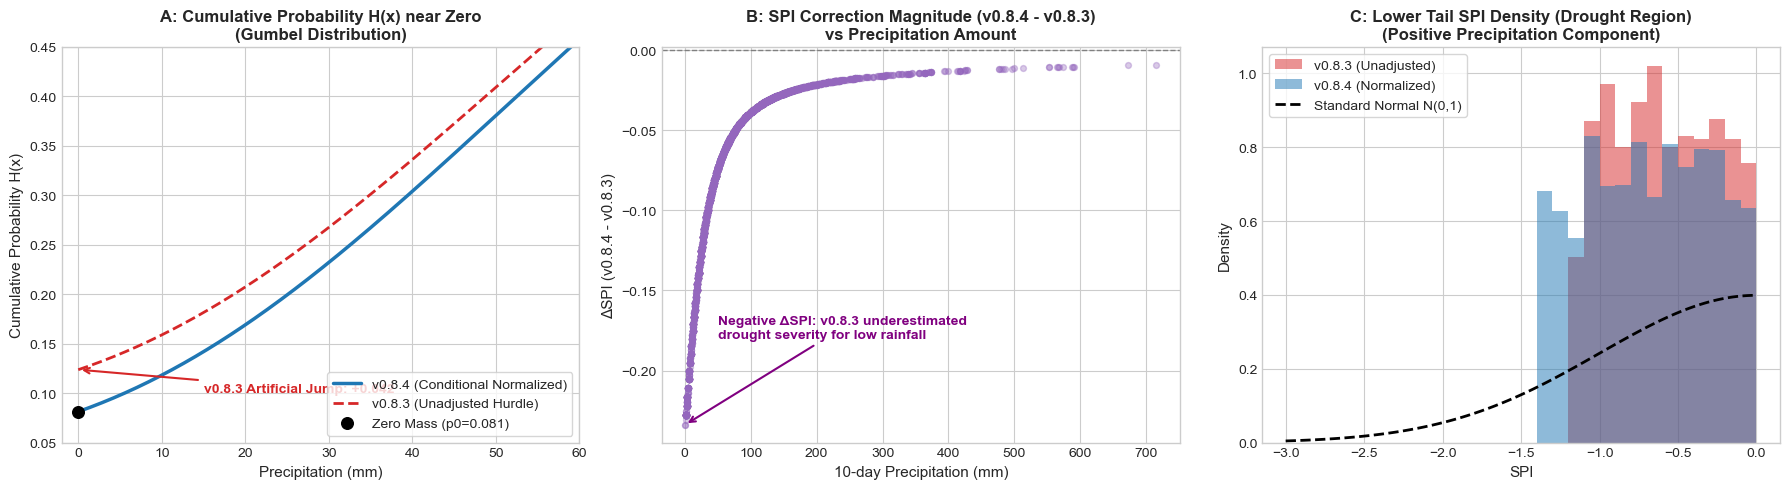

In [13]:
# Figure 5: Visualizing Zero-Bound Discontinuity in v0.8.3 vs Continuity in v0.8.4
m_gum = Dist(agg, gumbel_r, prob_zero=True)
loc_g, scale_g = m_gum.loc, m_gum.scale
f0_g = float(gumbel_r.cdf(0.0, loc=loc_g, scale=scale_g))
p0_g = m_gum.p0

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel A: Cumulative Probability H(x) near Zero
x_eval = np.linspace(0.001, 60, 300)
H_v83 = p0_g + (1.0 - p0_g) * gumbel_r.cdf(x_eval, loc=loc_g, scale=scale_g)
H_v84 = p0_g + (1.0 - p0_g) * np.clip((gumbel_r.cdf(x_eval, loc=loc_g, scale=scale_g) - f0_g) / (1.0 - f0_g), 0.0, 1.0)

axes[0].plot(x_eval, H_v84, color='#1f77b4', linewidth=2.5, label='v0.8.4 (Conditional Normalized)')
axes[0].plot(x_eval, H_v83, color='#d62728', linestyle='--', linewidth=2.0, label='v0.8.3 (Unadjusted Hurdle)')
axes[0].scatter([0], [p0_g], color='black', s=70, zorder=5, label=f'Zero Mass (p0={p0_g:.3f})')
axes[0].annotate(f'v0.8.3 Artificial Jump: +{(1-p0_g)*f0_g:.3f}', 
                 xy=(0.1, p0_g + (1-p0_g)*f0_g), xytext=(15, p0_g + 0.02),
                 arrowprops=dict(arrowstyle='->', color='#d62728', lw=1.5), color='#d62728', fontweight='bold')
axes[0].set_title('A: Cumulative Probability H(x) near Zero\n(Gumbel Distribution)', fontweight='bold')
axes[0].set_xlabel('Precipitation (mm)')
axes[0].set_ylabel('Cumulative Probability H(x)')
axes[0].set_xlim(-2, 60)
axes[0].set_ylim(0.05, 0.45)
axes[0].legend(loc='lower right', frameon=True)

# Panel B: Delta SPI vs Precipitation Amount
pos_agg = agg[agg > 0]
cdf_v84_all = m_gum.cdf()
spi_v84_all = pd.Series(norm.ppf(np.clip(cdf_v84_all, 1e-15, 1 - 1e-15)), index=agg.index)
vals_raw_all = np.asarray(m_gum.dist.cdf(agg.values, loc=loc_g, scale=scale_g))
m_zero_agg = (agg == 0.0).sum()
n_obs_agg = len(agg)
vals_v83_all = p0_g + (1.0 - p0_g) * vals_raw_all
vals_v83_all[agg.values == 0.0] = (m_zero_agg + 1.0) / (2.0 * (n_obs_agg + 1.0))
spi_v83_all = pd.Series(norm.ppf(np.clip(vals_v83_all, 1e-15, 1 - 1e-15)), index=agg.index)
delta_spi_all = spi_v84_all[pos_agg.index] - spi_v83_all[pos_agg.index]

axes[1].scatter(pos_agg, delta_spi_all, alpha=0.35, color='#9467bd', s=18)
axes[1].axhline(0, color='gray', linestyle='--', lw=1)
axes[1].set_title('B: SPI Correction Magnitude (v0.8.4 - v0.8.3)\nvs Precipitation Amount', fontweight='bold')
axes[1].set_xlabel('10-day Precipitation (mm)')
axes[1].set_ylabel('ΔSPI (v0.8.4 - v0.8.3)')
axes[1].annotate('Negative ΔSPI: v0.8.3 underestimated\ndrought severity for low rainfall',
                 xy=(pos_agg.min(), delta_spi_all.min()), xytext=(50, -0.18),
                 arrowprops=dict(arrowstyle='->', color='purple', lw=1.5), color='purple', fontweight='bold')

# Panel C: Lower Tail SPI Density (Drought Region)
bins_tail = np.linspace(-3, 0, 31)
axes[2].hist(spi_v83_all[agg > 0], bins=bins_tail, alpha=0.5, density=True, color='#d62728', label='v0.8.3 (Unadjusted)')
axes[2].hist(spi_v84_all[agg > 0], bins=bins_tail, alpha=0.5, density=True, color='#1f77b4', label='v0.8.4 (Normalized)')
x_norm_tail = np.linspace(-3, 0, 100)
axes[2].plot(x_norm_tail, norm.pdf(x_norm_tail), 'k--', lw=2, label='Standard Normal N(0,1)')
axes[2].set_title('C: Lower Tail SPI Density (Drought Region)\n(Positive Precipitation Component)', fontweight='bold')
axes[2].set_xlabel('SPI')
axes[2].set_ylabel('Density')
axes[2].legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()


## 10. Comprehensive Synthesis Table: Evolution from v0.8.2 to v0.8.4
Consolidated matrix comparing all aspects of distribution fitting and model selection between v0.8.2 and v0.8.3.

In [14]:
# Consolidated Synthesis Matrix: SPEI v0.8.2 vs v0.8.3 vs v0.8.4
summary_data = [
    {
        'Evaluation Dimension': 'Candidate Distribution Coverage',
        'v0.8.2 Baseline': '3 distributions (Gamma, Weibull, Gumbel)',
        'v0.8.3 Framework': '7 distributions (+ Lognormal, Fisk, Pearson-III, GenExtreme)',
        'v0.8.4 Enhanced (Current)': '7 distributions (+ Lognormal, Fisk, Pearson-III, GenExtreme)',
        'Significance': 'Accommodates heavy-tailed & flexible hydrologic rainfall regimes'
    },
    {
        'Evaluation Dimension': 'Zero-Bound Normalization (F(x | X>0))',
        'v0.8.2 Baseline': '❌ Raw unconditioned H(x)',
        'v0.8.3 Framework': '❌ Unadjusted H(x) in cdf(), causing jump at zero for F(0)>0',
        'v0.8.4 Enhanced (Current)': '✔ Conditional CDF F(x|X>0) = [F(x)-F(0)]/[1-F(0)] in cdf/ppf/pdf',
        'Significance': 'Eliminates boundary jump & drought tail bias in Pearson-III, GEV, Gumbel'
    },
    {
        'Evaluation Dimension': 'K-S Test Hypothesis Testing',
        'v0.8.2 Baseline': 'Naive asymptotic p-value (invalid for fitted params)',
        'v0.8.3 Framework': 'Parametric bootstrap with sample refitting (B >= 999)',
        'v0.8.4 Enhanced (Current)': 'Parametric bootstrap with sample refitting (B >= 999)',
        'Significance': 'Solves composite hypothesis Lilliefors bias (Stagge et al. 2015)'
    },
    {
        'Evaluation Dimension': 'Tail Goodness-of-Fit (A-D)',
        'v0.8.2 Baseline': 'None (tail errors undetected)',
        'v0.8.3 Framework': 'Anderson-Darling bootstrap p-value',
        'v0.8.4 Enhanced (Current)': 'Anderson-Darling bootstrap p-value',
        'Significance': 'Critical for accurate extreme drought & extreme wet quantification'
    },
    {
        'Evaluation Dimension': 'SPI Normality Verification (S-W)',
        'v0.8.2 Baseline': 'None (assumed standard normal)',
        'v0.8.3 Framework': 'Shapiro-Wilk test with tied zero replacement',
        'v0.8.4 Enhanced (Current)': 'Shapiro-Wilk test with tied zero replacement',
        'Significance': 'Ensures standardized index actually follows N(0,1) distribution'
    },
    {
        'Evaluation Dimension': 'Model Selection Policy',
        'v0.8.2 Baseline': 'Unconstrained minimum AIC',
        'v0.8.3 Framework': 'Delta-AIC < 2.0 + Bootstrap GOF filter + Parsimony rule',
        'v0.8.4 Enhanced (Current)': 'Delta-AIC < 2.0 + Bootstrap GOF filter + Parsimony rule',
        'Significance': 'Prevents overfitting; prioritizes parsimonious 2-parameter models'
    },
    {
        'Evaluation Dimension': 'Seasonal Diagnostics',
        'v0.8.2 Baseline': 'Single global fit',
        'v0.8.3 Framework': 'Cross-group rejection frequencies across monthly groups',
        'v0.8.4 Enhanced (Current)': 'Cross-group rejection frequencies across monthly groups',
        'Significance': 'Evaluates temporal robustness across seasons (Stagge methodology)'
    }
]

df_synthesis = pd.DataFrame(summary_data)
pd.set_option('display.max_colwidth', None)
print("=== Summary Matrix: SPEI v0.8.2 vs v0.8.3 vs v0.8.4 ===")
print(df_synthesis.to_string(index=False))


=== Summary Matrix: SPEI v0.8.2 vs v0.8.3 vs v0.8.4 ===
                 Evaluation Dimension                                      v0.8.2 Baseline                                             v0.8.3 Framework                                        v0.8.4 Enhanced (Current)                                                             Significance
      Candidate Distribution Coverage             3 distributions (Gamma, Weibull, Gumbel) 7 distributions (+ Lognormal, Fisk, Pearson-III, GenExtreme)     7 distributions (+ Lognormal, Fisk, Pearson-III, GenExtreme)         Accommodates heavy-tailed & flexible hydrologic rainfall regimes
Zero-Bound Normalization (F(x | X>0))                             ❌ Raw unconditioned H(x)  ❌ Unadjusted H(x) in cdf(), causing jump at zero for F(0)>0 ✔ Conditional CDF F(x|X>0) = [F(x)-F(0)]/[1-F(0)] in cdf/ppf/pdf Eliminates boundary jump & drought tail bias in Pearson-III, GEV, Gumbel
          K-S Test Hypothesis Testing Naive asymptotic p-value (invalid fo

## 11. Conclusion & Scientific References

### Key Scientific Conclusions
5. **Resolution of Zero-Bound Normalization (v0.8.4):** Stagge et al. (2015) restricted SPI candidate distributions to 2-parameter families with a lower bound at zero to avoid non-zero cumulative probability at zero ($F(0) > 0$). While SPEI extends candidates to 3-parameter hydrologic families (Pearson III, GEV, Gumbel), v0.8.4 strictly enforces conditional CDF normalization $F(x \mid X > 0) = [F(x) - F(0)] / [1 - F(0)]$ in `Dist.cdf()` and `Dist.ppf()`. This mathematically aligns the SPI transformation with the bootstrap goodness-of-fit and conditional AIC tests, removing artificial boundary discontinuities.

1. **The Composite Hypothesis Fallacy:** Standard Kolmogorov-Smirnov p-values (used in v0.8.2) can give misleadingly optimistic fit indications (e.g. Gamma naive p = 0.0878) because the critical values do not account for parameters estimated from the same sample. The parametric bootstrap calibration in v0.8.3 corrects for this bias.
2. **Tail Misfits Detected by Anderson-Darling:** The Anderson-Darling test implemented in v0.8.3 reveals that distributions with acceptable general CDF shapes often fail in the extreme tails. In operational drought monitoring, tail fidelity directly dictates the accuracy of severe and extreme drought declarations.
3. **Multi-Model Seasonal Selection:** Rather than enforcing a static global Gamma distribution, applying `model_selection.py` across monthly fitting groups demonstrates that different seasons favor different distribution families (e.g., Weibull and GenExtreme in transitional months, Pearson-III in others).
4. **Impact on Drought Event Frequency:** Using the calibrated v0.8.3 distribution refines drought severity estimations, particularly for severe ($\le -1.5$) and extreme ($\le -2.0$) drought thresholds.

---

### Scientific References
- **Stagge, J.H., Tallaksen, L.M., Gudmundsson, L., Van Loon, A.F., & Stahl, K. (2015).**  
  *Candidate Distributions for Climatological Drought Indices (SPI and SPEI).*  
  International Journal of Climatology, 35(13), 4027–4040. DOI: [10.1002/joc.4267](https://doi.org/10.1002/joc.4267).
- **Burnham, K.P., & Anderson, D.R. (2002).**  
  *Model Selection and Multimodel Inference: A Practical Information-Theoretic Approach (2nd ed.).*  
  Springer-Verlag, New York.
- **McKee, T.B., Doesken, N.J., & Kleist, J. (1993).**  
  *The relationship of drought frequency and duration to time scales.*  
  Proceedings of the 8th Conference on Applied Climatology, 17(22), 179–183.
- **Vicente-Serrano, S.M., Beguería, S., & López-Moreno, J.I. (2010).**  
  *A multiscalar drought index sensitive to global warming: the Standardized Precipitation Evapotranspiration Index.*  
  Journal of Climate, 23(7), 1696–1718.
- **Gül, G.Ö., & Güçlü, Y.S. (2025).**  
  *A modified standardized precipitation index (M-SPI) for extreme dry and wet spells monitoring.*  
  Theoretical and Applied Climatology. DOI: [10.1007/s00704-024-05335-5](https://doi.org/10.1007/s00704-024-05335-5).